# Impact of nudging on the land state

**Question.** H2OSOI, TSOI and TWS at 1 m jump when a free coupled spin-up hands over to a nudged run. This happens in both branches (CTRL and LCC). This notebook asks:
1. **How large is the effect of nudging itself?** PD has a clean test: the **met run** `NF2000norbc_tropstratchem_met_f19_f19_20260422`.
   - It is the free continuation of the PD spin-up (same forcing, 2000–2014), and it supplied the nudging winds.
   - So `CTRL_PD − PD_met` over the same years (2001–2009) is the **nudging effect**: same forcing, same large-scale weather, only the relaxation differs.
   - `PD_met − PD_spinup` is the free decade-to-decade difference (variability or residual drift).
2. **How large is the FUT jump?** By design, FUT runs are nudged to the **PD** winds (user decision, 2026-10-22). No free FUT met run exists, so the FUT jump cannot be split into its two parts.
3. **Do CTRL and LCC drift in the same way during the nudged years?** If they do, the drift cancels in LCC − CTRL.

**Nudging set-up** (`cases-scripts/cases-setup.sh: setup_nudging_data`): u, v and PS only (`met_nudge_only_uvps`), relaxation time 6 h, the same met file for all nudged runs. Checked from `CaseDocs/atm_in` in §1.

**Variables:**
- short-term: TWS, H2OSOI and TSOI at 1.06 m;
- land drivers: TSA (2 m air temperature), precipitation (RAIN + SNOW), FSDS, FLDS, latent and sensible heat, transpiration (QVEGT), runoff, snow water (H2OSNO).

**Regions:** modified cells, >45°N unmodified, tropics 30°S–30°N, global land. Annual means are weighted by month length; spatial weights are area × landfrac.

Evidence tags: **(a)** verified · **(b)** inference · **(c)** unverified. Annual means are cached in `impact_of_nudging_on_land_outputs/cache/`.

In [1]:
import os
os.environ.setdefault('HDF5_USE_FILE_LOCKING', 'FALSE')  # before netCDF4/xarray import: HDF5 locking on /cluster/home corrupted cache files
from pathlib import Path
import re
import pickle
import warnings
import multiprocessing as mp
from concurrent.futures import ProcessPoolExecutor
import numpy as np
import pandas as pd
import xarray as xr
import netCDF4
import matplotlib.pyplot as plt
import cartopy.crs as ccrs
from scipy import stats

ARCHIVE = Path('/nird/datapeak/NS9188K/adelez/BRL-FRST-XPSN_archive')
CASE_ROOT = Path('~/cases/BRL_FRST_XPSN').expanduser()
MASK_FILE = Path('../check-simulation-equilibrium/lcc-modified-cells/modified_cells.nc')
OUT = Path('impact_of_nudging_on_land_outputs')
CACHE = OUT / 'cache'  # regenerable annual-mean .nc
CACHE.mkdir(parents=True, exist_ok=True)
REBUILD_CACHE = False
N_WORKERS = 8

# stage, period, branch, case, kind, start (x-axis offset in land years since the shared starting state)
STAGES = pd.DataFrame([
    ('PD_spinup',      'PD',  'shared', 'NF2000norbc_tropstratchem_spinup_f19_f19',                    'free',              0),
    ('PD_met',         'PD',  'MET',    'NF2000norbc_tropstratchem_met_f19_f19_20260422',              'free (met source)', 20),
    ('CTRL_PD',        'PD',  'CTRL',   'NF2000norbc_tropstratchem_nudg_ctrl_f19_f19-20260925',        'nudged',            20),
    ('PD_spinup_LCC',  'PD',  'LCC',    'NF2000norbc_tropstratchem_spinup_lcc_f19_f19-20260928',       'free',              120),
    ('LCC_PD',         'PD',  'LCC',    'NF2000norbc_tropstratchem_nudg_lcc_f19_f19-20261005',         'nudged',            140),
    ('FUT_spinup',     'FUT', 'shared', 'NF2100ssp585norbc_tropstratchem_spinup_f19_f19-3',            'free',              0),
    ('CTRL_FUT',       'FUT', 'CTRL',   'NF2100ssp585norbc_tropstratchem_nudg_ctrl_f19_f19-20260925',  'nudged',            20),
    ('FUT_spinup_LCC', 'FUT', 'LCC',    'NF2100ssp585norbc_tropstratchem_spinup_lcc_f19_f19-20260928', 'free',              120),
    ('LCC_FUT',        'FUT', 'LCC',    'NF2100ssp585norbc_tropstratchem_nudg_lcc_f19_f19-20261005',   'nudged',            140),
], columns=['stage', 'period', 'branch', 'case', 'kind', 'start']).set_index('stage')
# The LCC land-only stage (land years 21-120) is left out: no atmosphere, so not relevant for nudging.

SHORT = ['TWS', 'H2OSOI_1m', 'TSOI_1m']
DRIVERS = ['TSA', 'PRECIP', 'FSDS', 'FLDS', 'EFLX_LH_TOT', 'FSH', 'QVEGT', 'QRUNOFF', 'H2OSNO']
VARS = SHORT + DRIVERS
SOIL = {'H2OSOI_1m': 'H2OSOI', 'TSOI_1m': 'TSOI'}
SOIL_INDEX = 8  # levgrnd[8] = 1.06 m; levsoi = first 20 levgrnd levels (asserted)
PER_DAY = {'PRECIP', 'QVEGT', 'QRUNOFF'}  # mm/s -> mm/day for display
NUDGED_YEARS = (2001, 2009)
FREE_YEARS = 10  # last years of a free spin-up used as its reference
COLOR = {'shared': '0.35', 'MET': '#7b3294', 'CTRL': '#1f77b4', 'LCC': '#d95f02'}

## 1. Nudging set-up per case (from `CaseDocs/atm_in`)

In [2]:
def namelist(case, key, name='atm_in'):
    for root in (CASE_ROOT, CASE_ROOT / 'BRL_FRST_XPSN_archive'):
        f = root / case / 'CaseDocs' / name
        if f.is_file():
            m = re.search(rf'^\s*{key}\s*=\s*(.+?)\s*$', f.read_text(), re.M)
            return m.group(1).strip("'") if m else 'not set'
    return 'no CaseDocs'

setup = pd.DataFrame([dict(stage=s, kind=r.kind,
                           met_data_file=Path(namelist(r.case, 'met_data_file')).name,
                           met_nudge_only_uvps=namelist(r.case, 'met_nudge_only_uvps'),
                           met_rlx_time=namelist(r.case, 'met_rlx_time'))
                      for s, r in STAGES.iterrows()]).set_index('stage')
setup.to_csv(OUT / 'nudging_setup.csv')
display(setup)

,kind,met_data_file,met_nudge_only_uvps,met_rlx_time
stage,,,,
PD_spinup,free,not set,not set,not set
PD_met,free (met source),not set,not set,not set
CTRL_PD,nudged,NF2000norbc_tropstratchem_met_f19_f19_20260422...,.true.,6
PD_spinup_LCC,free,not set,not set,not set
LCC_PD,nudged,NF2000norbc_tropstratchem_met_f19_f19_20260422...,.true.,6
FUT_spinup,free,not set,not set,not set
CTRL_FUT,nudged,NF2000norbc_tropstratchem_met_f19_f19_20260422...,.true.,6
FUT_spinup_LCC,free,not set,not set,not set
LCC_FUT,nudged,NF2000norbc_tropstratchem_met_f19_f19_20260422...,.true.,6


## Loading annual means

Files are read with plain `netCDF4`, 8 at a time (~0.3 s per file on NIRD). Each `time_bounds` interval goes to its midpoint year, and incomplete years are dropped. Soil fields are taken at 1.06 m.

In [3]:
def hist_files(case):
    files = sorted((ARCHIVE / case / 'lnd/hist').glob('*.clm2.h0.*.nc'))
    if not files:
        raise FileNotFoundError(f'No clm2.h0 files for {case}')
    return files

def read_file(path):
    with netCDF4.Dataset(path) as d:
        t = d['time']
        assert t.calendar == 'noleap' and re.fullmatch(r'days since \d{4}-01-01( 00:00:00)?', t.units), (path, t.units)
        bounds = d['time_bounds'][:].astype(float)
        mid = bounds.mean(1)
        out = dict(mid=mid, year=int(t.units.split()[2][:4]) + np.floor(mid / 365).astype(int),
                   days=bounds[:, 1] - bounds[:, 0])
        get = lambda v: np.ma.filled(d[v][:].astype(float), np.nan)
        for v in VARS:
            if v in d.variables:
                out[v] = get(v)
        if {'RAIN', 'SNOW'} <= set(d.variables):
            out['PRECIP'] = get('RAIN') + get('SNOW')
        for new, old in SOIL.items():
            assert abs(float(d['levgrnd'][SOIL_INDEX]) - 1.06) < 0.01, f'{path}: soil levels changed'
            out[new] = np.ma.filled(d[old][:, SOIL_INDEX].astype(float), np.nan)
    return out

def annual_means(case):
    files = hist_files(case)
    try:
        with ProcessPoolExecutor(N_WORKERS, mp_context=mp.get_context('fork')) as pool:
            parts = list(pool.map(read_file, files))
    except pickle.PicklingError:  # cells exec'd outside a kernel: read serially
        parts = [read_file(f) for f in files]
    mid = np.concatenate([p['mid'] for p in parts])
    if len(np.unique(mid)) != len(mid):
        raise ValueError(f'{case}: duplicated time steps')
    year = np.concatenate([p['year'] for p in parts])
    days = np.concatenate([p['days'] for p in parts])
    keep = [y for y in np.unique(year) if abs(days[year == y].sum() - 365) < 0.5]
    with netCDF4.Dataset(files[0]) as d:
        coords = dict(lat=d['lat'][:].data, lon=d['lon'][:].data)
        grid = {v: (('lat', 'lon'), np.ma.filled(d[v][:].astype(float), np.nan)) for v in ('area', 'landfrac')}
        units = {v: d[SOIL.get(v, 'RAIN' if v == 'PRECIP' else v)].units for v in VARS
                 if SOIL.get(v, 'RAIN' if v == 'PRECIP' else v) in d.variables}
    data = {}
    for v in [v for v in VARS if all(v in p for p in parts)]:
        x = np.concatenate([p[v] for p in parts])
        rows = []
        for y in keep:
            sel = year == y
            total = np.nansum(x[sel] * days[sel][:, None, None], 0)
            total[np.isnan(x[sel]).all(0)] = np.nan
            rows.append(total / days[sel].sum())
        data[v] = (('year', 'lat', 'lon'), np.stack(rows), {'units': units.get(v, '?')})
    return xr.Dataset({**data, **grid}, coords=dict(year=keep, **coords))

def load_stage(stage):
    path = CACHE / f'annual_{stage}.nc'
    if path.is_file() and not REBUILD_CACHE:
        try:
            with xr.open_dataset(path) as ds:
                return ds.load()
        except OSError:
            print(f'{path.name}: unreadable cache, rebuilding')
    ann = annual_means(STAGES.loc[stage, 'case'])
    tmp = path.with_name(path.stem + '.tmp.nc')
    ann.to_netcdf(tmp)
    os.replace(tmp, path)
    return ann

ANN = {stage: load_stage(stage) for stage in STAGES.index}
ref = ANN['CTRL_PD']
for stage, a in ANN.items():
    assert np.array_equal(a.lat, ref.lat) and np.array_equal(a.lon, ref.lon), stage
    assert np.allclose(a.landfrac, ref.landfrac, equal_nan=True), stage
print(pd.Series({s: f"{int(a.year[0])}–{int(a.year[-1])} ({a.sizes['year']} yr); missing: "
                    f"{', '.join(v for v in VARS if v not in a) or '-'}" for s, a in ANN.items()}).to_string())

PD_spinup              1–20 (20 yr); missing: -
PD_met            2000–2014 (15 yr); missing: -
CTRL_PD           2000–2009 (10 yr); missing: -
PD_spinup_LCC        1–20 (20 yr); missing: TWS
LCC_PD            2000–2009 (10 yr); missing: -
FUT_spinup             1–20 (20 yr); missing: -
CTRL_FUT          2000–2009 (10 yr); missing: -
FUT_spinup_LCC       1–20 (20 yr); missing: TWS
LCC_FUT           2000–2009 (10 yr); missing: -


In [4]:
mask = xr.open_dataset(MASK_FILE).modified.astype(bool)
assert np.allclose(mask.lat, ref.lat) and np.allclose(mask.lon, ref.lon)
mask = mask.assign_coords(lat=ref.lat, lon=ref.lon)
LAND = ref.landfrac > 0
LAT = ref.lat.broadcast_like(LAND)
REGIONS = {
    'modified cells': LAND & mask,
    '>45N unmodified': LAND & (LAT > 45) & ~mask,
    'tropics 30S-30N': LAND & (abs(LAT) <= 30),
    'global land': LAND,
}
W = ref.area * ref.landfrac

def scaled(stage, v):
    field = ANN[stage][v]
    return field * 86400 if v in PER_DAY else field

def units_of(v):
    stage = next(s for s in STAGES.index if v in ANN[s])
    return 'mm/day' if v in PER_DAY else ANN[stage][v].attrs.get('units', '?')

def regional_mean(field, region):
    w = W.where(REGIONS[region] & np.isfinite(field))
    return (field * w).sum(('lat', 'lon')) / w.sum(('lat', 'lon'))

SERIES = {(s, r, v): regional_mean(scaled(s, v), r) for s in STAGES.index for r in REGIONS for v in VARS if v in ANN[s]}

def window(stage):
    # Reference years: nudged runs and the met run use NUDGED_YEARS; free spin-ups their last FREE_YEARS
    a = ANN[stage]
    if STAGES.loc[stage, 'kind'] == 'free':
        return slice(int(a.year[-FREE_YEARS]), int(a.year[-1]))
    return slice(*NUDGED_YEARS)

def xaxis(stage, years):
    return STAGES.loc[stage, 'start'] + (years - int(ANN[stage].year[0]) + 1)

## 2. Free → nudged along the lineage

Grey = shared free spin-up, purple = PD met run (free, the source of the nudging winds), blue = CTRL nudged, orange = LCC (free coupled spin-up, then nudged). Dotted verticals mark free → nudged hand-overs.
The LCC land-only stage (land years 21–120) is left out.

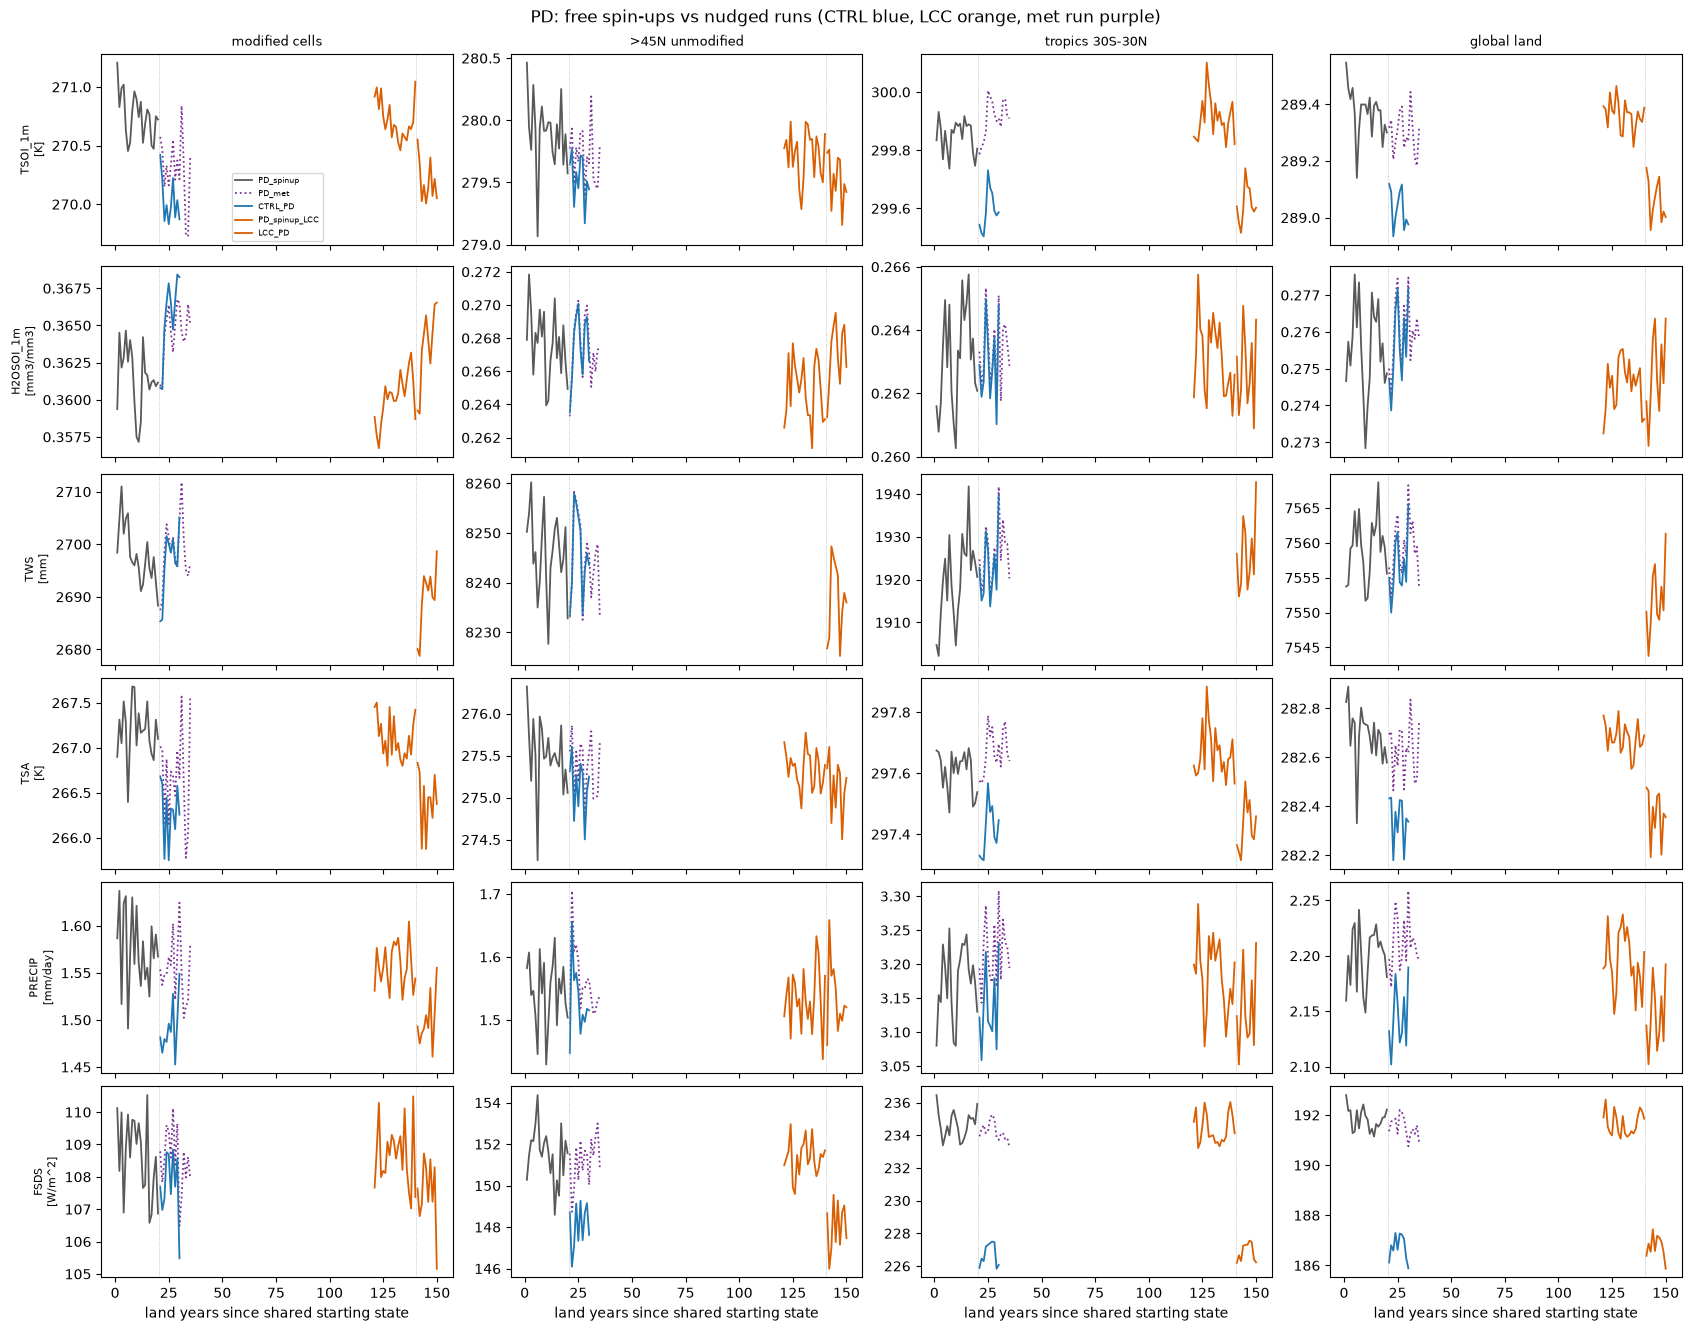

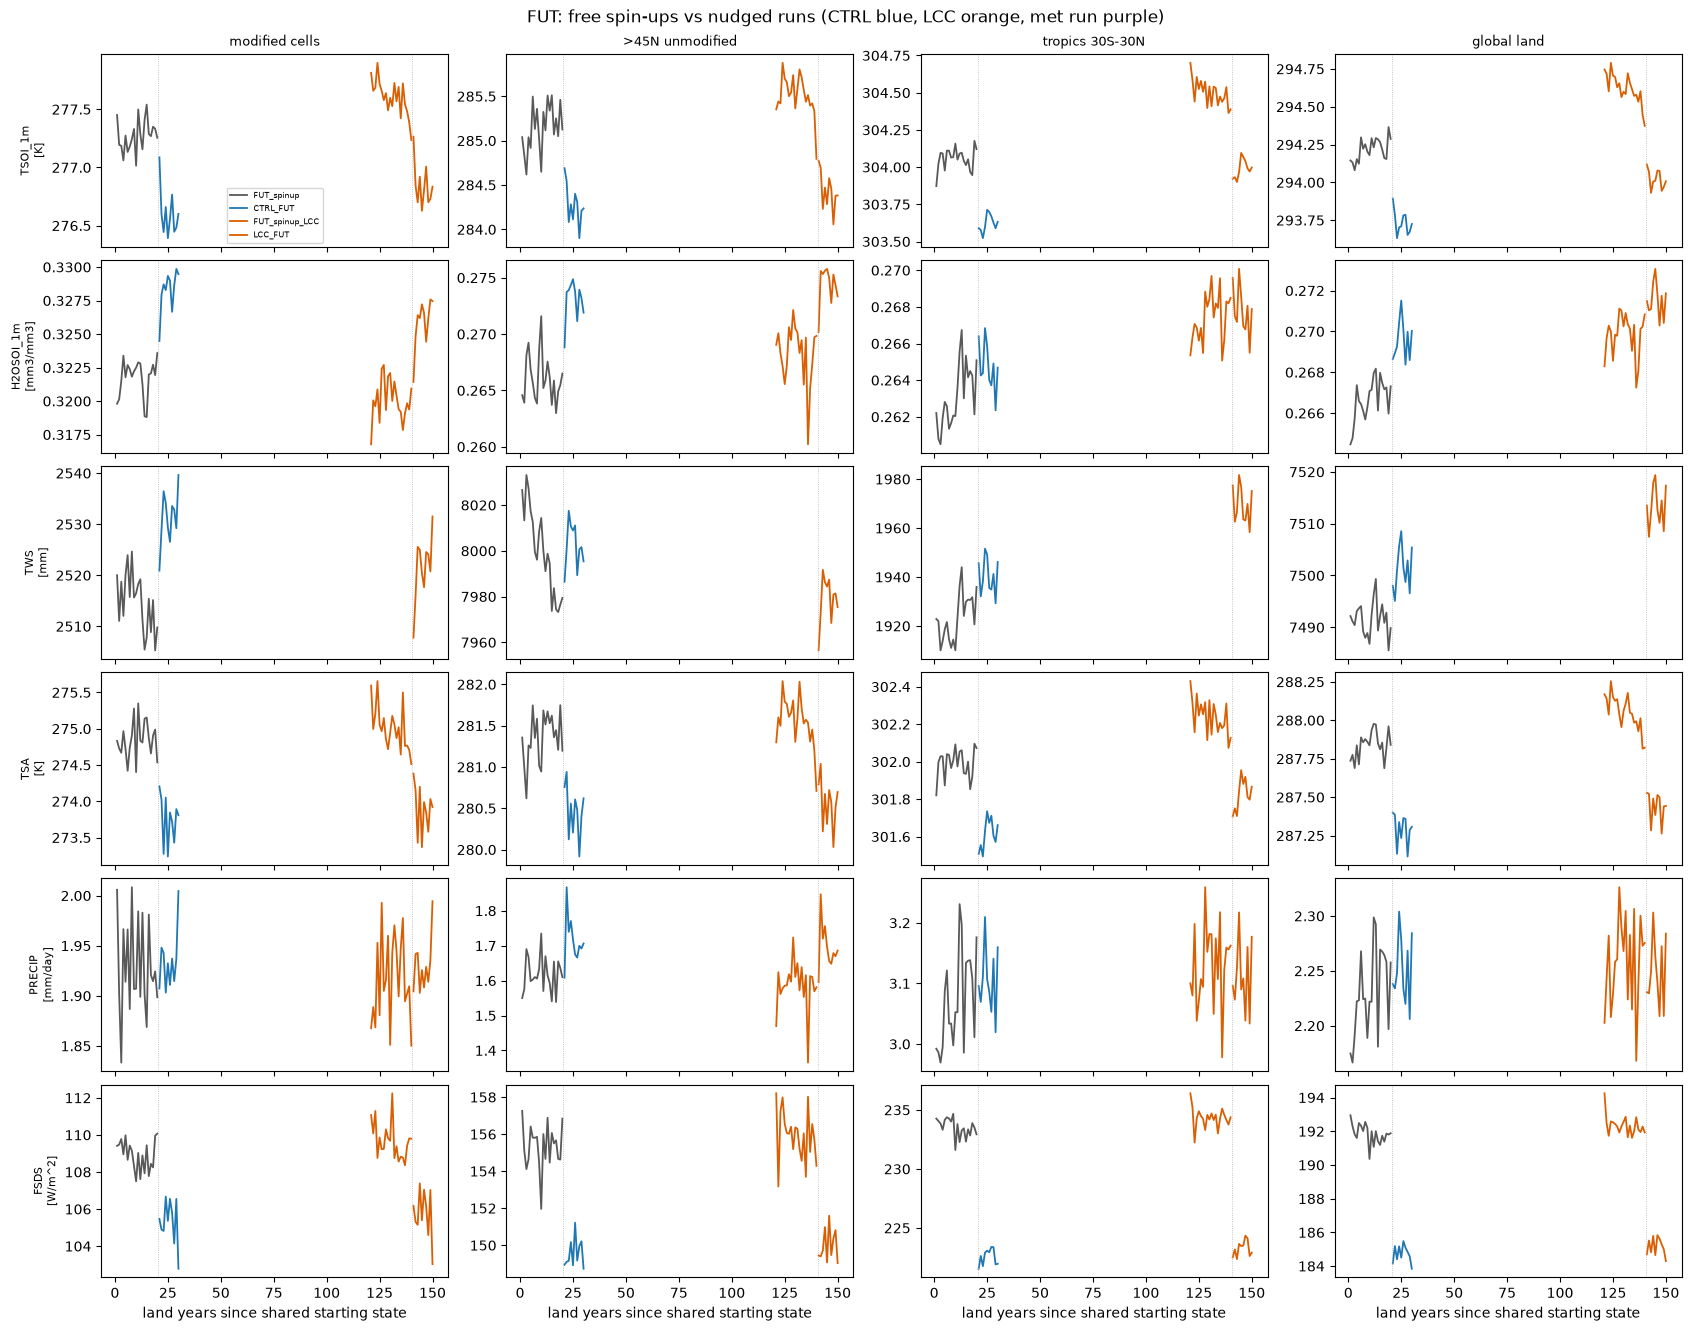

In [5]:
PLOT_VARS = ['TSOI_1m', 'H2OSOI_1m', 'TWS', 'TSA', 'PRECIP', 'FSDS']
for period in ('PD', 'FUT'):
    group = STAGES[STAGES.period == period]
    fig, axes = plt.subplots(len(PLOT_VARS), len(REGIONS), figsize=(4.2 * len(REGIONS), 2.2 * len(PLOT_VARS)),
                             sharex=True, layout='constrained')
    for i, v in enumerate(PLOT_VARS):
        for j, region in enumerate(REGIONS):
            ax = axes[i, j]
            for stage, s in group.iterrows():
                if (stage, region, v) in SERIES:
                    y = SERIES[stage, region, v]
                    ax.plot(xaxis(stage, y.year), y, color=COLOR[s.branch], lw=1.3,
                            ls=':' if s.branch == 'MET' else '-', label=stage)
            for x in (20.5, 140.5):
                ax.axvline(x, color='0.7', lw=0.6, ls=':')
            if i == 0:
                ax.set_title(region, fontsize=9)
            if j == 0:
                ax.set_ylabel(f'{v}\n[{units_of(v)}]', fontsize=8)
    axes[0, 0].legend(fontsize=6)
    for ax in axes[-1]:
        ax.set_xlabel('land years since shared starting state')
    fig.suptitle(f'{period}: free spin-ups vs nudged runs (CTRL blue, LCC orange, met run purple)')
    fig.savefig(OUT / f'fig1_lineage_{period}.png', dpi=150)
    plt.show()

## 3. PD: decomposing the jump into free variability and the nudging effect

- **Δ1 = PD_met − PD_spinup**: free run 2001–2009 minus the last 10 spin-up years. Same model, same forcing, a different free decade: variability or residual drift.
- **Δ2 = CTRL_PD − PD_met**: same years and the same large-scale weather (the nudging winds come from PD_met). This is the **effect of nudging**. p-values come from a paired t-test on the 9 annual differences.

Both are shown in units of PD_met's interannual SD. Δ1 + Δ2 is the total jump that a nudged run inherits from its free spin-up.

units     spinup        met     nudged  \
region          variable                                                
modified cells  TWS               mm  2694.3412  2699.0066  2697.6976   
                H2OSOI_1m    mm3/mm3     0.3609     0.3648     0.3661   
                TSOI_1m            K   270.6843   270.3084   269.9867   
                TSA                K   267.1747   266.6331   266.2361   
                PRECIP        mm/day     1.5626     1.5639     1.4926   
                FSDS           W/m^2   108.1551   108.7286   107.7568   
                FLDS           W/m^2   254.2967   252.3550   250.6605   
                EFLX_LH_TOT    W/m^2    18.6970    18.5422    17.7915   
                FSH            W/m^2     9.6195     9.7993     9.6226   
                QVEGT         mm/day     0.2270     0.2242     0.2121   
                QRUNOFF       mm/day     0.9270     0.9223     0.8757   
                H2OSNO            mm   409.3359   409.3164   408.3807   
>45N unmodified TWS               mm  8243.9256  8247.8167  8247.0265   
                H2OSOI_1m    mm3/mm3     0.2670     0.2683     0.2679   
                TSOI_1m            K   279.8447   279.7152   279.5173   
                TSA                K   275.4186   275.3808   275.1131   
                PRECIP        mm/day     1.5483     1.5860     1.5393   
                FSDS           W/m^2   150.9344   150.7668   147.9744   
                FLDS           W/m^2   273.3952   273.7762   273.2409   
                EFLX_LH_TOT    W/m^2    26.6271    26.6087    25.7337   
                FSH            W/m^2    19.6982    19.9239    19.3711   
                QVEGT         mm/day     0.4252     0.4207     0.4082   
                QRUNOFF       mm/day     0.5445     0.5789     0.5686   
                H2OSNO            mm  1270.2223  1270.6827  1270.9954   
tropics 30S-30N TWS               mm  1924.8240  1925.1749  1922.9223   
                H2OSOI_1m    mm3/mm3     0.2638     0.2634     0.2630   
                TSOI_1m            K   299.8530   299.9102   299.6012   
                TSA                K   297.6014   297.6721   297.4233   
                PRECIP        mm/day     3.1963     3.2173     3.1366   
                FSDS           W/m^2   234.5408   234.4815   226.8292   
                FLDS           W/m^2   376.7625   377.1234   376.9507   
                EFLX_LH_TOT    W/m^2    55.8666    55.7663    54.2679   
                FSH            W/m^2    53.5869    53.5412    50.7635   
                QVEGT         mm/day     0.9719     0.9702     0.9530   
                QRUNOFF       mm/day     1.2612     1.2885     1.2598   
                H2OSNO            mm     0.0992     0.0814     0.0679   
global land     TWS               mm  7559.7765  7559.4136  7556.8170   
                H2OSOI_1m    mm3/mm3     0.2756     0.2761     0.2757   
                TSOI_1m            K   289.3514   289.2998   289.0232   
                TSA                K   282.6583   282.6147   282.3337   
                PRECIP        mm/day     2.2074     2.2157     2.1451   
                FSDS           W/m^2   191.6527   191.6582   186.7824   
                FLDS           W/m^2   309.9205   309.8303   309.3067   
                EFLX_LH_TOT    W/m^2    37.3428    37.2142    36.0397   
                FSH            W/m^2    34.3464    34.3660    32.7548   
                QVEGT         mm/day     0.6179     0.6155     0.6003   
                QRUNOFF       mm/day     0.8602     0.8718     0.8454   
                H2OSNO            mm  1106.5722  1106.5318  1106.3341   

                             d1_free  d2_nudging  iav_sd  d1_in_iav  \
region          variable                                              
modified cells  TWS           4.6654     -1.3090  4.6772     0.9975   
                H2OSOI_1m     0.0039      0.0013  0.0019     2.0581   
                TSOI_1m      -0.3758     -0.3217  0.1392    -2.6989   
                TSA      

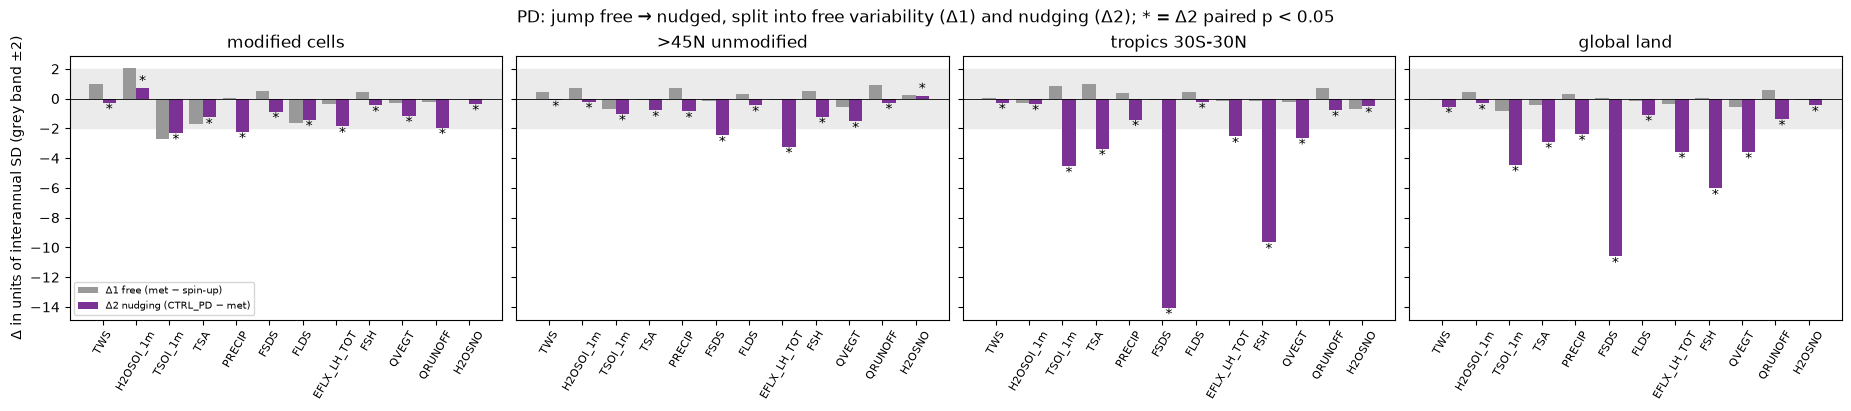

In [6]:
rows = []
for region in REGIONS:
    for v in VARS:
        spin = SERIES['PD_spinup', region, v].sel(year=window('PD_spinup'))
        met = SERIES['PD_met', region, v].sel(year=window('PD_met'))
        nud = SERIES['CTRL_PD', region, v].sel(year=window('CTRL_PD'))
        assert list(met.year.values) == list(nud.year.values)
        sd = float(met.std(ddof=1))
        d1, d2 = float(met.mean() - spin.mean()), float(nud.mean() - met.mean())
        rows.append(dict(region=region, variable=v, units=units_of(v), spinup=float(spin.mean()), met=float(met.mean()),
                         nudged=float(nud.mean()), d1_free=d1, d2_nudging=d2, iav_sd=sd,
                         d1_in_iav=d1 / sd, d2_in_iav=d2 / sd,
                         p_d2_paired=stats.ttest_rel(nud.values, met.values).pvalue))
decomp = pd.DataFrame(rows)
decomp.to_csv(OUT / 'pd_jump_decomposition.csv', index=False)
display(decomp.set_index(['region', 'variable']).round(4))

fig, axes = plt.subplots(1, len(REGIONS), figsize=(4.6 * len(REGIONS), 4), sharey=True, layout='constrained')
x = np.arange(len(VARS))
for ax, region in zip(axes, REGIONS):
    sub = decomp[decomp.region == region].set_index('variable')
    ax.bar(x - 0.2, sub.loc[VARS, 'd1_in_iav'], 0.4, color='0.6', label='Δ1 free (met − spin-up)')
    bars = ax.bar(x + 0.2, sub.loc[VARS, 'd2_in_iav'], 0.4, color='#7b3294', label='Δ2 nudging (CTRL_PD − met)')
    for b, p in zip(bars, sub.loc[VARS, 'p_d2_paired']):
        if p < 0.05:
            ax.text(b.get_x() + b.get_width() / 2, b.get_height(), '*', ha='center', va='bottom' if b.get_height() > 0 else 'top')
    ax.axhline(0, color='k', lw=0.6)
    ax.axhspan(-2, 2, color='0.92', zorder=0)
    ax.set(xticks=x, title=region)
    ax.set_xticklabels(VARS, rotation=60, fontsize=8)
axes[0].set_ylabel('Δ in units of interannual SD (grey band ±2)')
axes[0].legend(fontsize=7)
fig.suptitle('PD: jump free → nudged, split into free variability (Δ1) and nudging (Δ2); * = Δ2 paired p < 0.05')
fig.savefig(OUT / 'fig2_pd_decomposition.png', dpi=150)
plt.show()

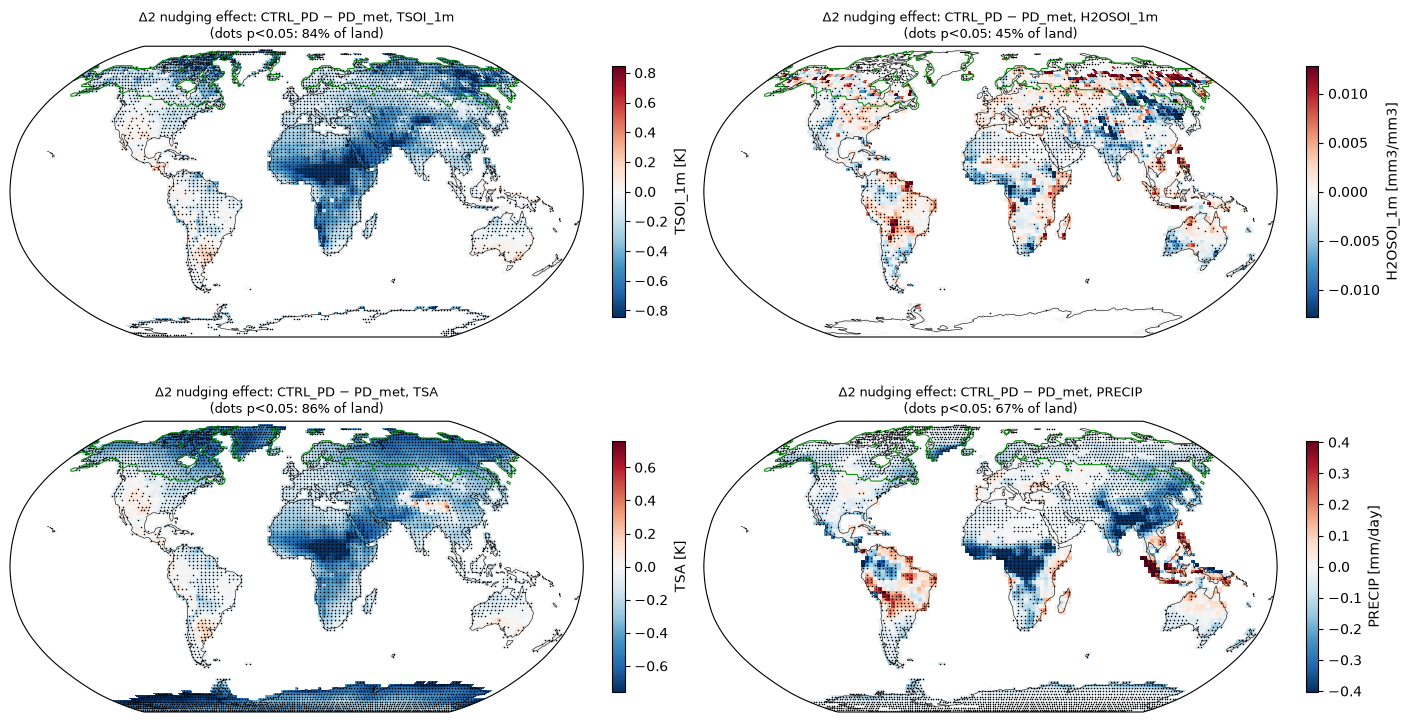

In [7]:
MAP_VARS = ['TSOI_1m', 'H2OSOI_1m', 'TSA', 'PRECIP']
yrs = slice(*NUDGED_YEARS)
fig, axes = plt.subplots(2, 2, figsize=(14, 7.5), subplot_kw=dict(projection=ccrs.Robinson()), layout='constrained')
for ax, v in zip(axes.flat, MAP_VARS):
    met, nud = scaled('PD_met', v).sel(year=yrs), scaled('CTRL_PD', v).sel(year=yrs)
    d = (nud - met).mean('year').where(LAND)
    with warnings.catch_warnings(), np.errstate(all='ignore'):
        warnings.simplefilter('ignore')
        p = stats.ttest_rel(nud.values, met.values, axis=0).pvalue
    lim = float(np.nanpercentile(abs(d), 98))
    m = ax.pcolormesh(d.lon, d.lat, d, transform=ccrs.PlateCarree(), cmap='RdBu_r', vmin=-lim, vmax=lim, shading='nearest')
    sig = (p < 0.05) & np.isfinite(d.values)
    yy, xx = np.meshgrid(d.lat, d.lon, indexing='ij')
    ax.scatter(xx[sig], yy[sig], s=1.2, c='k', lw=0, transform=ccrs.PlateCarree())
    ax.contour(mask.lon, mask.lat, mask.astype(int), levels=[0.5], colors='g', linewidths=0.7, transform=ccrs.PlateCarree())
    ax.coastlines(lw=0.4)
    ax.set_global()
    fig.colorbar(m, ax=ax, shrink=0.7, label=f'{v} [{units_of(v)}]')
    w = W.where(LAND & np.isfinite(d))
    ax.set_title(f'Δ2 nudging effect: CTRL_PD − PD_met, {v}\n(dots p<0.05: {float(w.where(sig).sum() / w.sum()):.0%} of land)', fontsize=9)
fig.savefig(OUT / 'fig3_pd_nudging_effect_maps.png', dpi=150)
plt.show()

## 4. Total jump free → nudged: PD vs FUT, CTRL and LCC branches

Jump = nudged run (2001–2009) − its preceding free spin-up (last 10 years), in units of the nudged run's interannual SD.
- PD CTRL: this is Δ1 + Δ2 from §3.
- FUT: the jump cannot be split, because there is no free FUT met run. FUT is nudged to **PD** winds by design, so its jump also contains the mismatch between PD circulation and 2100 thermodynamics (b).

pair                         PD CTRL  PD LCC  FUT CTRL  FUT LCC
variable    region                                             
EFLX_LH_TOT >45N unmodified  -0.8934 -0.5304   -0.1070   0.1374
            global land      -1.3031 -1.1165   -1.0674  -1.2079
            modified cells   -0.9055 -0.8037   -1.2906  -1.3984
            tropics 30S-30N  -1.5986 -1.2925   -1.3028  -1.5620
FLDS        >45N unmodified  -0.1543 -0.0854   -1.6721  -1.5622
            global land      -0.6138 -0.6717   -0.8187  -0.9240
            modified cells   -3.6363 -2.5881   -3.7892  -3.1430
            tropics 30S-30N   0.1882 -0.1194   -0.0091  -0.1154
FSDS        >45N unmodified  -2.9599 -3.5280   -5.9106  -5.4939
            global land      -4.8703 -4.8061   -6.8449  -6.9513
            modified cells   -0.3982 -1.0887   -3.4544  -3.7157
            tropics 30S-30N  -7.7115 -7.3103  -10.4954 -10.9119
FSH         >45N unmodified  -0.3271 -0.8974   -1.3408  -1.1311
            global land      -1.5916 -1.7047   -1.9581  -2.0730
            modified cells    0.0030 -0.3185   -0.1711  -0.1930
            tropics 30S-30N  -2.8234 -2.8253   -3.8784  -4.1442
H2OSNO      >45N unmodified   0.7732  1.7886  -16.0284 -10.4409
            global land      -0.2381  0.0738   -3.0571  -1.9169
            modified cells   -0.9552 -0.1038   -4.5804  -3.5327
            tropics 30S-30N  -0.0313 -0.0454    0.0036   0.0025
H2OSOI_1m   >45N unmodified   0.0009  0.0030    0.0080   0.0072
            global land       0.0002  0.0004    0.0024   0.0018
            modified cells    0.0052  0.0030    0.0070   0.0066
            tropics 30S-30N  -0.0008 -0.0000    0.0001  -0.0003
PRECIP      >45N unmodified  -0.0091  0.0087    0.1177   0.1297
            global land      -0.0623 -0.0445    0.0021  -0.0078
            modified cells   -0.0700 -0.0583    0.0091   0.0087
            tropics 30S-30N  -0.0597 -0.0377   -0.0109  -0.0170
QRUNOFF     >45N unmodified   0.0241  0.0330    0.1385   0.1427
            global land      -0.0148 -0.0080    0.0445   0.0428
            modified cells   -0.0513 -0.0398    0.0511   0.0570
            tropics 30S-30N  -0.0014 -0.0005    0.0415   0.0416
QVEGT       >45N unmodified  -0.0169 -0.0069   -0.0108  -0.0032
            global land      -0.0177 -0.0145   -0.0095  -0.0098
            modified cells   -0.0149 -0.0135   -0.0198  -0.0234
            tropics 30S-30N  -0.0189 -0.0151   -0.0079  -0.0099
TSA         >45N unmodified  -0.3056 -0.2605   -1.0697  -0.9324
            global land      -0.3246 -0.3113   -0.5911  -0.5665
            modified cells   -0.9385 -0.6631   -1.2273  -1.0670
            tropics 30S-30N  -0.1782 -0.2170   -0.3640  -0.3579
TSOI_1m     >45N unmodified  -0.3273 -0.2828   -1.0446  -1.0638
            global land      -0.3283 -0.3044   -0.5388  -0.5581
            modified cells   -0.6976 -0.4829   -0.7882  -0.7339
            tropics 30S-30N  -0.2519 -0.2842   -0.4304  -0.4601
TWS         >45N unmodified   3.1010     NaN   19.4571      NaN
            global land      -2.9594     NaN    9.4066      NaN
            modified cells    3.3564     NaN   20.6544      NaN
            tropics 30S-30N  -1.9017     NaN    9.0356      NaN

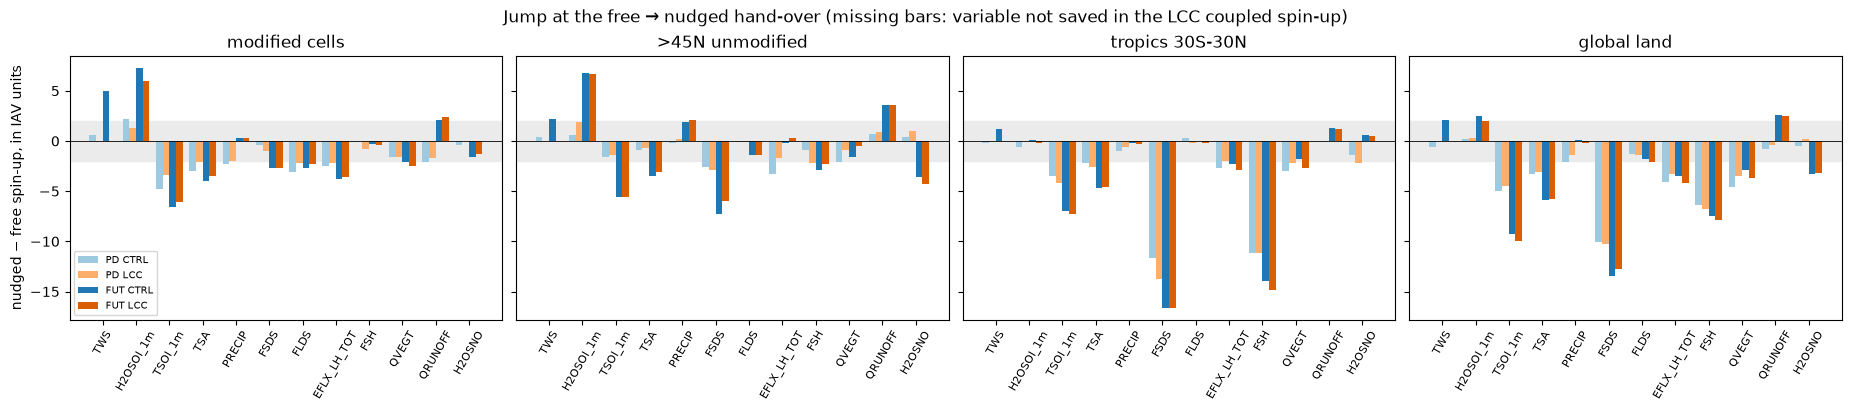

In [8]:
PAIRS = {'PD CTRL': ('PD_spinup', 'CTRL_PD'), 'PD LCC': ('PD_spinup_LCC', 'LCC_PD'),
         'FUT CTRL': ('FUT_spinup', 'CTRL_FUT'), 'FUT LCC': ('FUT_spinup_LCC', 'LCC_FUT')}
rows = []
for name, (free, nud) in PAIRS.items():
    for region in REGIONS:
        for v in VARS:
            if (free, region, v) not in SERIES:
                continue
            f = SERIES[free, region, v].sel(year=window(free))
            n = SERIES[nud, region, v].sel(year=window(nud))
            sd = float(n.std(ddof=1))
            rows.append(dict(pair=name, region=region, variable=v, units=units_of(v),
                             jump=float(n.mean() - f.mean()), jump_in_iav=float(n.mean() - f.mean()) / sd,
                             p_welch=stats.ttest_ind(n.values, f.values, equal_var=False).pvalue))
jumps = pd.DataFrame(rows)
jumps.to_csv(OUT / 'jumps_free_to_nudged.csv', index=False)
display(jumps.pivot_table(index=['variable', 'region'], columns='pair', values='jump')[list(PAIRS)].round(4))

fig, axes = plt.subplots(1, len(REGIONS), figsize=(4.6 * len(REGIONS), 4), sharey=True, layout='constrained')
colors = {'PD CTRL': '#9ecae1', 'PD LCC': '#fdae6b', 'FUT CTRL': '#1f77b4', 'FUT LCC': '#d95f02'}
x = np.arange(len(VARS))
for ax, region in zip(axes, REGIONS):
    sub = jumps[jumps.region == region].set_index(['pair', 'variable']).jump_in_iav
    for k, name in enumerate(PAIRS):
        vals = [sub.get((name, v), np.nan) for v in VARS]
        ax.bar(x + (k - 1.5) * 0.2, vals, 0.2, color=colors[name], label=name)
    ax.axhline(0, color='k', lw=0.6)
    ax.axhspan(-2, 2, color='0.92', zorder=0)
    ax.set(xticks=x, title=region)
    ax.set_xticklabels(VARS, rotation=60, fontsize=8)
axes[0].set_ylabel('nudged − free spin-up, in IAV units')
axes[0].legend(fontsize=7)
fig.suptitle('Jump at the free → nudged hand-over (missing bars: variable not saved in the LCC coupled spin-up)')
fig.savefig(OUT / 'fig4_jumps_pd_fut.png', dpi=150)
plt.show()

## 5. Drift during the nudged years: is it the same in CTRL and LCC?

For each period, region and variable, over 2001–2009:
- OLS trend of CTRL, of LCC, and of the **difference series LCC − CTRL**;
- the standard error of the difference trend, corrected for lag-1 autocorrelation of the residuals (n_eff = n(1 − r₁)/(1 + r₁), at least 3);
- **flag `drift_differs` if p < 0.05.** If the drift is the same in both members, it cancels in LCC − CTRL.

With only 9 years, trends are uncertain: about 1 in 20 tests will be flagged by chance.

In [9]:
def trend_test(y):
    x = y.year.values.astype(float)
    slope, icpt = np.polyfit(x, y.values, 1)
    res = y.values - (slope * x + icpt)
    n = len(x)
    r1 = np.corrcoef(res[:-1], res[1:])[0, 1] if n > 3 else 0.0
    n_eff = float(np.clip(n * (1 - r1) / (1 + r1), 3, n))
    se = np.sqrt(np.sum(res ** 2) / (n - 2) / np.sum((x - x.mean()) ** 2)) * np.sqrt((n - 2) / max(n_eff - 2, 1))
    p = 2 * stats.t.sf(abs(slope / se), max(n_eff - 2, 1)) if se > 0 else np.nan
    return 10 * slope, 10 * se, p, n_eff

rows = []
for period in ('PD', 'FUT'):
    for region in REGIONS:
        for v in VARS:
            c = SERIES[f'CTRL_{period}', region, v].sel(year=slice(*NUDGED_YEARS))
            l = SERIES[f'LCC_{period}', region, v].sel(year=slice(*NUDGED_YEARS))
            tc, tl = trend_test(c)[0], trend_test(l)[0]
            td, se, p, neff = trend_test(l - c)
            rows.append(dict(period=period, region=region, variable=v, units=units_of(v) + '/decade',
                             trend_CTRL=tc, trend_LCC=tl, trend_diff=td, se_diff=se, n_eff=neff, p_diff=p,
                             diff_vs_member=abs(td) / max(abs(tc), abs(tl), 1e-30), drift_differs=p < 0.05))
drift = pd.DataFrame(rows)
drift.to_csv(OUT / 'drift_same_in_both_members.csv', index=False)
print(f"Flagged (p < 0.05): {int(drift.drift_differs.sum())} of {len(drift)} tests (≈{0.05 * len(drift):.0f} expected by chance)")
display(drift[drift.variable.isin(SHORT)].set_index(['period', 'region', 'variable']).round(4))
display(drift[drift.drift_differs].set_index(['period', 'region', 'variable']).round(4))

Flagged (p < 0.05): 9 of 96 tests (≈5 expected by chance)


units  trend_CTRL  trend_LCC  \
period region          variable                                           
PD     modified cells  TWS             mm/decade     11.6609    12.6131   
                       H2OSOI_1m  mm3/mm3/decade      0.0063     0.0060   
                       TSOI_1m          K/decade     -0.1051    -0.0709   
       >45N unmodified TWS             mm/decade    -11.4172    -6.6560   
                       H2OSOI_1m  mm3/mm3/decade      0.0003     0.0002   
                       TSOI_1m          K/decade     -0.2113    -0.2152   
       tropics 30S-30N TWS             mm/decade     13.7205    15.6461   
                       H2OSOI_1m  mm3/mm3/decade      0.0007     0.0008   
                       TSOI_1m          K/decade      0.0738     0.0626   
       global land     TWS             mm/decade      8.5277    10.8296   
                       H2OSOI_1m  mm3/mm3/decade      0.0019     0.0020   
                       TSOI_1m          K/decade     -0.0510    -0.0537   
FUT    modified cells  TWS             mm/decade      3.7780     8.3234   
                       H2OSOI_1m  mm3/mm3/decade      0.0013     0.0019   
                       TSOI_1m          K/decade      0.0137    -0.0025   
       >45N unmodified TWS             mm/decade    -18.1011    -8.0579   
                       H2OSOI_1m  mm3/mm3/decade     -0.0023    -0.0026   
                       TSOI_1m          K/decade     -0.2353    -0.2431   
       tropics 30S-30N TWS             mm/decade     -0.9244    -1.9666   
                       H2OSOI_1m  mm3/mm3/decade     -0.0017    -0.0015   
                       TSOI_1m          K/decade      0.0731     0.0778   
       global land     TWS             mm/decade      2.0953     2.0610   
                       H2OSOI_1m  mm3/mm3/decade     -0.0003    -0.0005   
                       TSOI_1m          K/decade     -0.0231    -0.0318   

                                  trend_diff  se_diff   n_eff  p_diff  \
period region          variable                                         
PD     modified cells  TWS            0.9522   1.0034  3.6363  0.4613   
                       H2OSOI_1m     -0.0003   0.0011  3.0000  0.8242   
                       TSOI_1m        0.0343   0.0102  9.0000  0.0123   
       >45N unmodified TWS            4.7612   0.6134  5.1313  0.0038   
                       H2OSOI_1m     -0.0001   0.0002  6.4172  0.7292   
                       TSOI_1m       -0.0039   0.0093  9.0000  0.6903   
       tropics 30S-30N TWS            1.9256   1.7723  5.5600  0.3453   
                       H2OSOI_1m      0.0001   0.0002  9.0000  0.6285   
                       TSOI_1m       -0.0112   0.0132  7.4339  0.4314   
       global land     TWS            2.3019   0.5028  8.3515  0.0033   
                       H2OSOI_1m      0.0001   0.0001  9.0000  0.1709   
                       TSOI_1m       -0.0027   0.0057  9.0000  0.6470   
FUT    modified cells  TWS            4.5454   2.9001  3.1312  0.3402   
                       H2OSOI_1m      0.0006   0.0005  7.0543  0.2522   
                       TSOI_1m       -0.0162   0.0108  9.0000  0.1773   
       >45N unmodified TWS           10.0432   1.3157  7.2074  0.0005   
                       H2OSOI_1m     -0.0003   0.0004  6.7481  0.5514   
                       TSOI_1m       -0.0078   0.0201  9.0000  0.7104   
       tropics 30S-30N TWS           -1.0422   1.2413  9.0000  0.4289   
                       H2OSOI_1m      0.0002   0.0003  9.0000  0.5148   
                       TSOI_1m        0.0047   0.0118  9.0000  0.7023   
       global land     TWS           -0.0343   0.7143  9.0000  0.9630   
                       H2OSOI_1m     -0.0002   0.0002  9.0000  0.3734   
                       TSOI_1m       -0.0087   0.0091  9.0000  0.3701   

                                  diff_vs_member  drift_differs  
period region          variable                                  
PD     modified cells  TWS                0.0755          Fal

units  trend_CTRL  trend_LCC  \
period region          variable                                            
PD     modified cells  TSOI_1m           K/decade     -0.1051    -0.0709   
                       QVEGT        mm/day/decade      0.0104     0.0038   
                       H2OSNO           mm/decade      0.4967    -0.7939   
       >45N unmodified TWS              mm/decade    -11.4172    -6.6560   
       global land     TWS              mm/decade      8.5277    10.8296   
                       H2OSNO           mm/decade      0.3212     0.1546   
FUT    >45N unmodified TWS              mm/decade    -18.1011    -8.0579   
                       H2OSNO           mm/decade    -14.9860    -6.6528   
       tropics 30S-30N EFLX_LH_TOT   W/m^2/decade     -0.0695     0.2575   

                                    trend_diff  se_diff   n_eff  p_diff  \
period region          variable                                           
PD     modified cells  TSOI_1m          0.0343   0.0102  9.0000  0.0123   
                       QVEGT           -0.0066   0.0018  6.9143  0.0139   
                       H2OSNO          -1.2906   0.3426  7.0939  0.0126   
       >45N unmodified TWS              4.7612   0.6134  5.1313  0.0038   
       global land     TWS              2.3019   0.5028  8.3515  0.0033   
                       H2OSNO          -0.1666   0.0438  9.0000  0.0066   
FUT    >45N unmodified TWS             10.0432   1.3157  7.2074  0.0005   
                       H2OSNO           8.3332   0.7700  4.6698  0.0028   
       tropics 30S-30N EFLX_LH_TOT      0.3271   0.1299  9.0000  0.0399   

                                    diff_vs_member  drift_differs  
period region          variable                                    
PD     modified cells  TSOI_1m              0.3261           True  
                       QVEGT                0.6366           True  
                       H2OSNO               1.6257           True  
       >45N unmodified TWS                  0.4170           True  
       global land     TWS                  0.2126           True  
                       H2OSNO               0.5186           True  
FUT    >45N unmodified TWS                  0.5548           True  
                       H2OSNO               0.5561           True  
       tropics 30S-30N EFLX_LH_TOT          1.2701           True

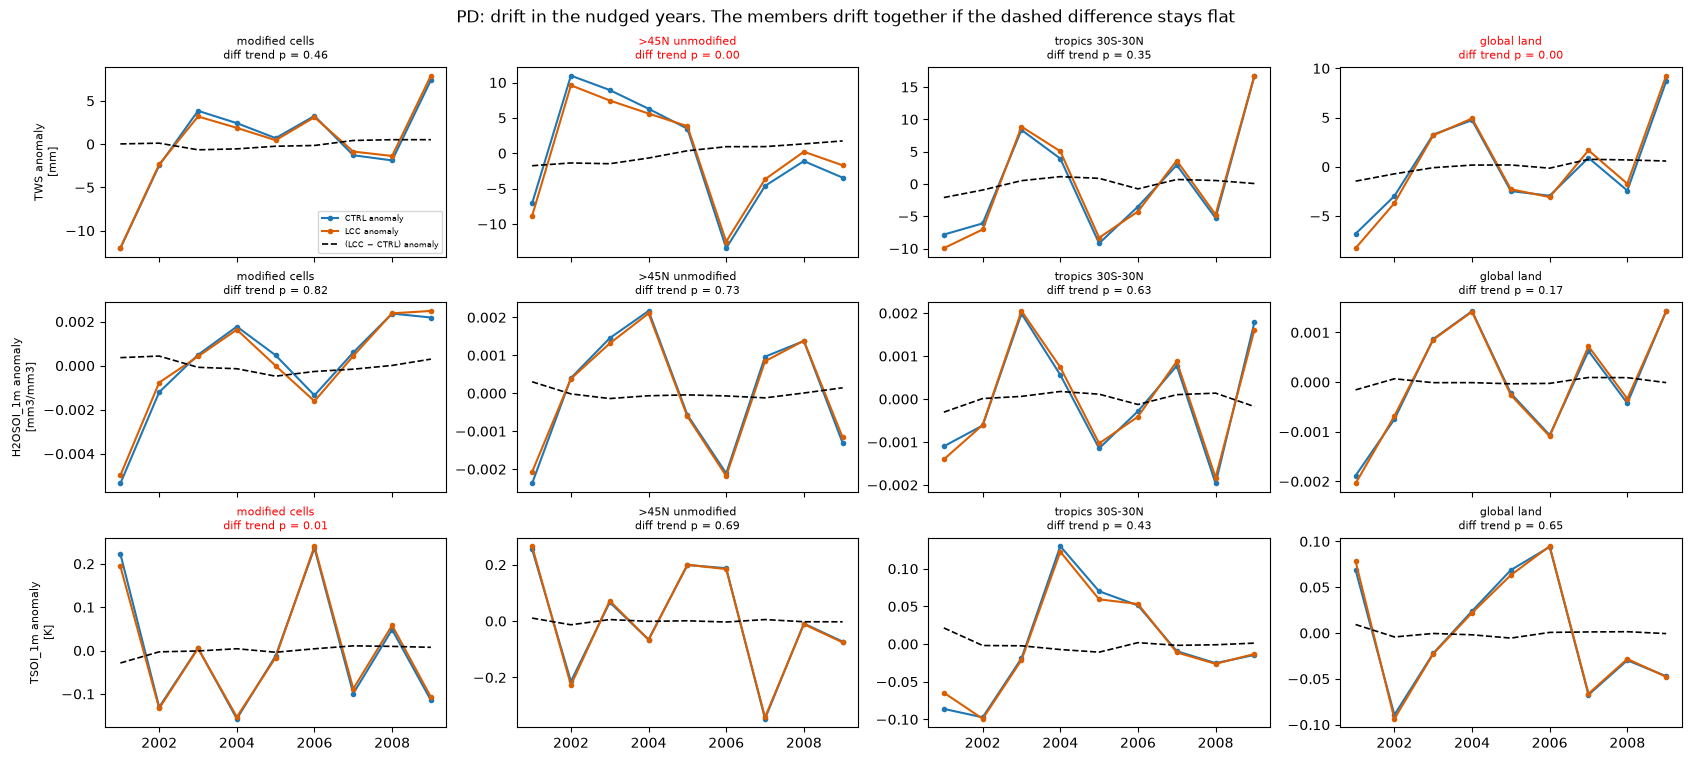

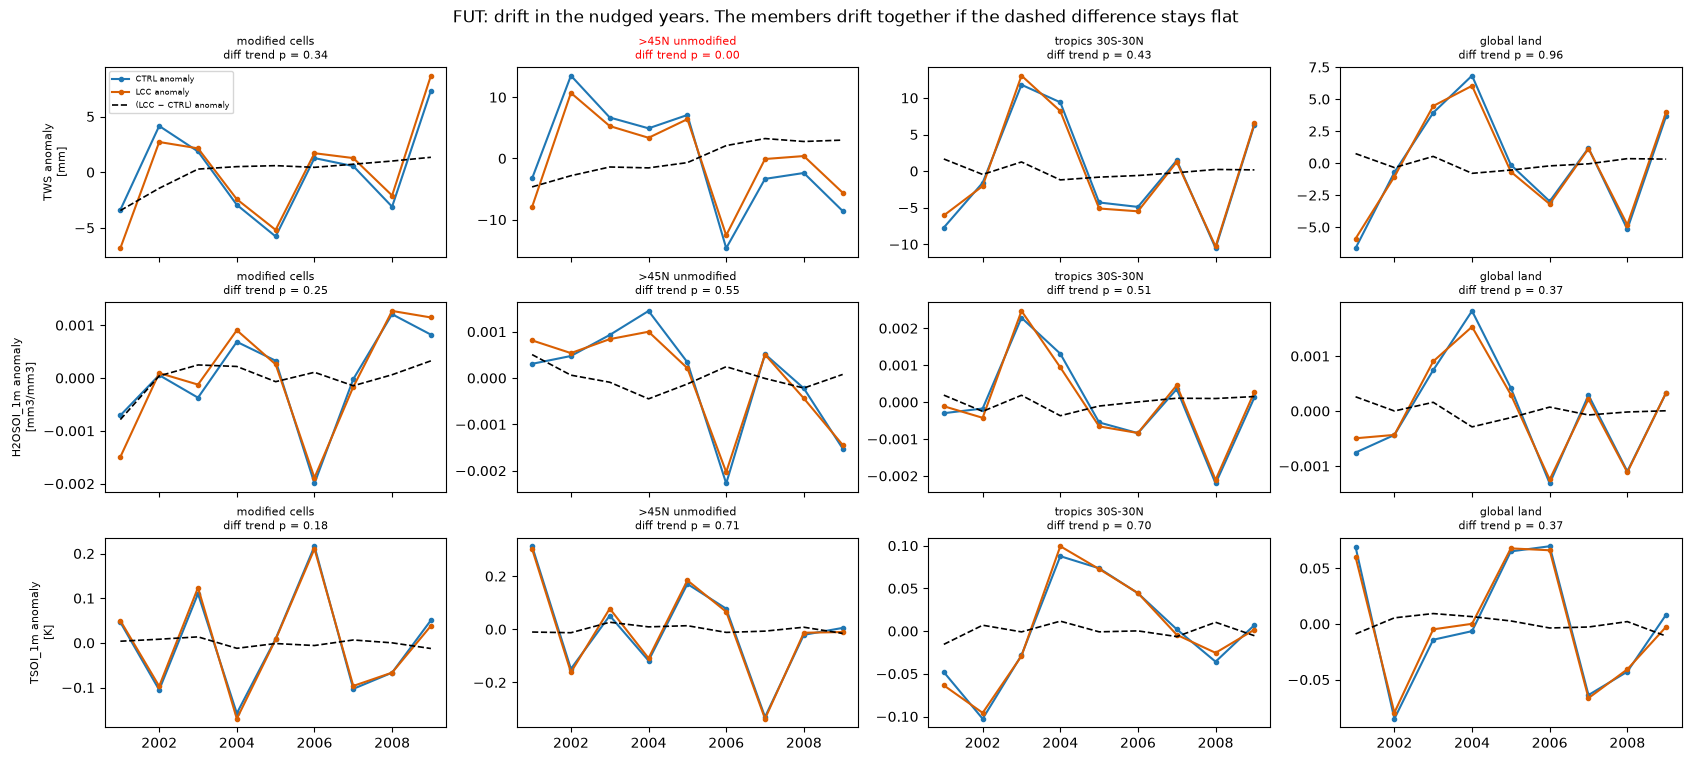

In [10]:
for period in ('PD', 'FUT'):
    fig, axes = plt.subplots(len(SHORT), len(REGIONS), figsize=(4.2 * len(REGIONS), 2.5 * len(SHORT)),
                             sharex=True, layout='constrained')
    for i, v in enumerate(SHORT):
        for j, region in enumerate(REGIONS):
            ax = axes[i, j]
            c = SERIES[f'CTRL_{period}', region, v].sel(year=slice(*NUDGED_YEARS))
            l = SERIES[f'LCC_{period}', region, v].sel(year=slice(*NUDGED_YEARS))
            ax.plot(c.year, c - c.mean(), 'o-', ms=3, color=COLOR['CTRL'], label='CTRL anomaly')
            ax.plot(l.year, l - l.mean(), 'o-', ms=3, color=COLOR['LCC'], label='LCC anomaly')
            d = l - c
            ax.plot(d.year, d - d.mean(), 'k--', lw=1.2, label='(LCC − CTRL) anomaly')
            row = drift.set_index(['period', 'region', 'variable']).loc[(period, region, v)]
            ax.set_title(f'{region}\ndiff trend p = {row.p_diff:.2f}', fontsize=8, color='r' if row.drift_differs else 'k')
            if j == 0:
                ax.set_ylabel(f'{v} anomaly\n[{units_of(v)}]', fontsize=8)
    axes[0, 0].legend(fontsize=6)
    fig.suptitle(f'{period}: drift in the nudged years. The members drift together if the dashed difference stays flat')
    fig.savefig(OUT / f'fig5_drift_{period}.png', dpi=150)
    plt.show()

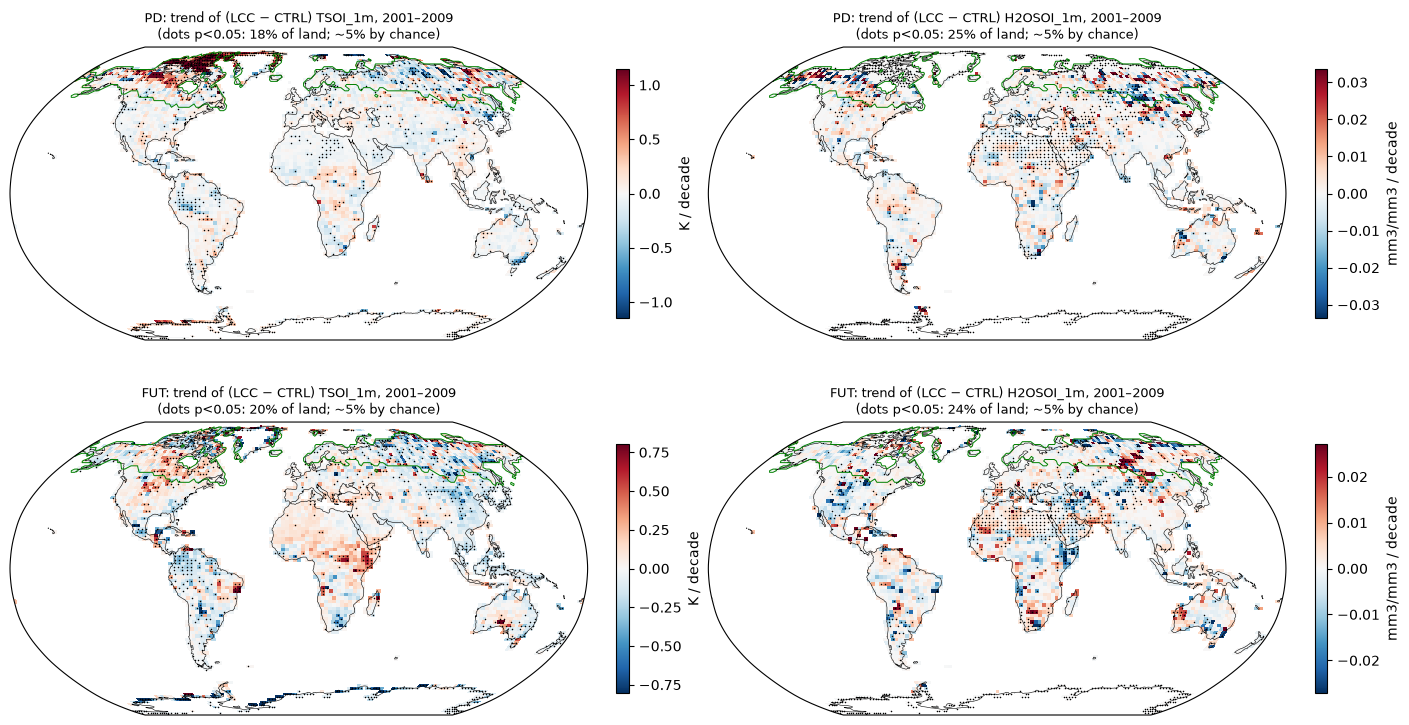

In [11]:
def cell_trend(field):
    # OLS slope per decade and plain p-value per cell (no autocorrelation correction in maps)
    x = field.year.values.astype(float)
    xa = x - x.mean()
    y = field.values
    slope = np.tensordot(xa, y - y.mean(0), axes=(0, 0)) / np.sum(xa ** 2)
    res = y - y.mean(0) - slope * xa[:, None, None]
    se = np.sqrt((res ** 2).sum(0) / (len(x) - 2) / np.sum(xa ** 2))
    with np.errstate(all='ignore'):
        p = 2 * stats.t.sf(abs(slope / se), len(x) - 2)
    return 10 * slope, p

fig, axes = plt.subplots(2, 2, figsize=(14, 7.5), subplot_kw=dict(projection=ccrs.Robinson()), layout='constrained')
for i, period in enumerate(['PD', 'FUT']):
    for j, v in enumerate(['TSOI_1m', 'H2OSOI_1m']):
        ax = axes[i, j]
        d = (scaled(f'LCC_{period}', v) - scaled(f'CTRL_{period}', v)).sel(year=slice(*NUDGED_YEARS))
        tr, p = cell_trend(d)
        tr = xr.DataArray(tr, coords=dict(lat=d.lat, lon=d.lon)).where(LAND)
        lim = float(np.nanpercentile(abs(tr), 98))
        m = ax.pcolormesh(tr.lon, tr.lat, tr, transform=ccrs.PlateCarree(), cmap='RdBu_r', vmin=-lim, vmax=lim, shading='nearest')
        sig = (p < 0.05) & np.isfinite(tr.values)
        yy, xx = np.meshgrid(tr.lat, tr.lon, indexing='ij')
        ax.scatter(xx[sig], yy[sig], s=1.2, c='k', lw=0, transform=ccrs.PlateCarree())
        ax.contour(mask.lon, mask.lat, mask.astype(int), levels=[0.5], colors='g', linewidths=0.7, transform=ccrs.PlateCarree())
        ax.coastlines(lw=0.4)
        ax.set_global()
        w = W.where(LAND & np.isfinite(tr))
        fig.colorbar(m, ax=ax, shrink=0.7, label=f'{units_of(v)} / decade')
        ax.set_title(f'{period}: trend of (LCC − CTRL) {v}, 2001–2009\n(dots p<0.05: {float(w.where(sig).sum() / w.sum()):.0%} of land; ~5% by chance)', fontsize=9)
fig.savefig(OUT / 'fig6_trend_of_difference_maps.png', dpi=150)
plt.show()

## Summary (run 2026-10-22; outputs saved in this notebook and in `impact_of_nudging_on_land_outputs/`)

👉 **The jump at the free → nudged hand-over is mainly the effect of nudging itself. Nudging makes the land cloudier and cooler. It is the same in CTRL and LCC, so it cancels in LCC − CTRL. The "drift" inside the nudged years is mostly the met-run weather sequence, shared by both members, not a spin-up adjustment.**

**1. Set-up (a, §1).** All four nudged runs (CTRL/LCC × PD/FUT) use the same PD met file, `met_nudge_only_uvps = .true.` and `met_rlx_time = 6`. FUT is nudged to PD winds by design.

**2. PD decomposition (a, §3, `pd_jump_decomposition.csv`).** The nudging effect Δ2 = CTRL_PD − PD_met, same years and same forcing, global land:
- FSDS −4.9 W m⁻² (−10.6 IAV; tropics −7.7 W m⁻², −14 IAV);
- sensible heat −1.6 W m⁻², latent heat −1.2 W m⁻²;
- TSA −0.28 K, **TSOI@1 m −0.28 K (−4.5 IAV)**;
- precipitation −0.07 mm/day; transpiration −0.015 mm/day;
- TWS −2.6 mm and H2OSOI −0.0004: both small (< 0.6 IAV).
- Paired p < 0.05 almost everywhere; TSOI and TSA significant over 84–86 % of land (fig. 3).
- Reading (b): relaxing u, v and PS every 6 h produces **more cloud and less sunshine at the surface**, so the land is cooler and evaporates less. Soil temperature carries the signal down to 1 m.
- The free decade-to-decade part Δ1 = PD_met − PD_spinup is mostly < 1 IAV. The exception is the modified cells (TSOI −0.38 K, −2.7 IAV; H2OSOI +2.1 IAV): boreal decadal variability or residual drift, not separable here (b).

**3. FUT jump (a, §4).** Larger than PD, in IAV units:

| Variable | Region | PD | FUT |
|---|---|---|---|
| TSOI@1 m | global land | −5 | −9 |
| FSDS | global land | −10 | −13.5 |
| H2OSOI@1 m | >45°N unmodified | +0.6 | **+6.8** |
| H2OSOI@1 m | modified cells | +2.2 | **+7.3** |
| TWS | modified cells | +0.6 | +5 |

FUT also has more runoff and less snow (H2OSNO −3.6 IAV at >45°N). Reading (b): on top of the nudging effect, the PD winds bring PD moisture transport and storm tracks into a 2100 climate, which makes the boreal soils wetter. It cannot be split further: there is no free FUT met run (c).
**In both periods the CTRL and LCC jumps are nearly identical** (e.g. FUT TSOI −9.2 vs −10.0 IAV global), so the jump cancels in LCC − CTRL (a).

**4. Is the drift the same in both members? (a, §5, `drift_same_in_both_members.csv`).** 9 of 96 tests are flagged at p < 0.05, against ~5 expected by chance.
- **Short-term variables:** H2OSOI@1 m is never flagged. TSOI@1 m is flagged only in PD modified cells (diff +0.034 K/decade against member trends of −0.07 to −0.11): small, and inside the region where LCC ≠ CTRL is expected.
- **TWS at >45°N unmodified is flagged in both periods.** LCC loses less water than CTRL: PD −6.7 vs −11.4 mm/decade, FUT −8.1 vs −18.1 mm/decade. Much of it is **snow**: FUT H2OSNO diff +8.3 of the +10 mm/decade. Relative to TWS ≈ 8000 mm this is ~0.1 %/decade.
- Fig. 5: CTRL and LCC have almost identical year-to-year anomalies (shared nudged weather). The 2001–2009 "trends" are mostly this weather sequence, not a slow adjustment, and they cancel in LCC − CTRL (b).

**Implications (b).**
- LCC − CTRL in the same period is robust to the nudging effect and to the nudged-year drift. The exceptions are TWS and snow at >45°N, which deserve a caveat (and in FUT also carry the CO₂ bug).
- **Absolute values** of nudged runs, and comparisons of nudged vs free runs, are biased by about −0.3 K soil/air temperature and −5 W m⁻² surface solar (global land, PD); more in FUT.
- **FUT − PD** comparisons of land variables include the effect of PD winds in a 2100 climate.

**Limits:** 9 nudged years; met run 2001–2009 only for the decomposition; maps without autocorrelation correction; the LCC coupled spin-ups lack TWS, so the LCC-branch TWS jump is missing.